In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

In [2]:
restaurant = pd.read_parquet("restaurant_Philadelphia.parquet")

review = pd.read_parquet("review_Philadelphia.parquet")

## PART A: DATA HEALTH

In [3]:
print("Duplicates")
print(f"Duplicate review_ids: {review['review_id'].duplicated().sum()}")
print(f"Duplicate texts: {review['text'].duplicated().sum()}")

Duplicates
Duplicate review_ids: 0
Duplicate texts: 1212


In [4]:
print("Unusable text")
print(f"Missing text values: {review['text'].isna().sum()}")
print(f"Reviews under 20 chars: {(review['text'].str.strip().str.len() < 20).sum()}")

Unusable text
Missing text values: 0
Reviews under 20 chars: 61


In [5]:
print("Length distribution (Word Count)")
word_counts = review['text'].str.split().str.len()
print(word_counts.describe())
print(f"Reviews over 512 words: {(word_counts > 512).sum()}")

Length distribution (Word Count)
count    687307.000000
mean        110.186410
std          97.654199
min           1.000000
25%          45.000000
50%          81.000000
75%         143.000000
max        1021.000000
Name: text, dtype: float64
Reviews over 512 words: 5317


In [6]:
print("Star distribution (Baseline)")
print(review['stars'].value_counts(normalize=True).sort_index().round(3))

Star distribution (Baseline)
stars
1    0.097
2    0.084
3    0.133
4    0.283
5    0.403
Name: proportion, dtype: float64


In [7]:
print("Date range")
review['date'] = pd.to_datetime(review['date'])
print(f"Date range: {review['date'].min().date()} to {review['date'].max().date()}")
print("Reviews per year (last 10 years):")
print(review['date'].dt.year.value_counts().sort_index().tail(10))

Date range
Date range: 2005-02-16 to 2022-01-19
Reviews per year (last 10 years):
date
2013    51597
2014    60250
2015    68208
2016    68748
2017    71947
2018    73190
2019    72182
2020    34860
2021    36717
2022     1849
Name: count, dtype: int64


In [8]:
print("Reviews per restaurant")
print(review.groupby('business_id').size().describe())

Reviews per restaurant
count    5854.000000
mean      117.408097
std       247.771985
min         5.000000
25%        14.000000
50%        40.000000
75%       118.000000
max      5778.000000
dtype: float64


- Data Cleanliness: The dataset is relatively clean (zero missing values, zero duplicate IDs). However, there are `1,212 duplicate texts`, and  `61 reviews under 20 characters`, basic text cleaning will strip out a negligible fraction of the overall data.
- The median review length is `81 words`, around `5,317 reviews` out of nearly `690,000` exceed 512 words. meaning we will rarely lose meaningful information to truncation (on basemodel).   
- Sentiment Imbalance: The Yelp ratings heavily skew positive, with 4-star and 5-star reviews making up 68.6% of the dataset. Because 5-star reviews alone are 40.3% of the data, there is a class imbalance which would affect the performance of the model and also may require class-weighting during training.   
- Temporal Relevance: Amount of reviews peaked between `2013` and `2019` (around` 60,000 to 73,000 reviews per year`) before dropping in `2020`. Since the dataset date back to 2005, there is a real chance that a large portion of the older reviews describe restaurants that may have changed management, menus, or closed entirely (No more reliable - worth looking into).   
- Recommender Sparsity: While the average restaurant has `117 reviews`, the median is `40`, and the bottom `25`% of the `5,854` restaurants have `14 or fewer reviews`. (Some of these restaurants may be new restaurants with little review, or we won't have enough data to get reliable result)

---

## cleaning data

In [9]:
original_count = len(review)

clean_review = review.drop_duplicates(subset=['text'])
clean_review = clean_review[clean_review['text'].str.strip().str.len() >= 20]


clean_review['date'] = pd.to_datetime(clean_review['date'])         # date to datetime 
clean_review = clean_review[clean_review['date'] >= '2015-01-01']   # drop pre-2015 reviews

business_counts = clean_review['business_id'].value_counts()        # Drop restaurants that have fewer than 15 reviews remaining
valid_businesses = business_counts[business_counts >= 15].index
clean_review = clean_review[clean_review['business_id'].isin(valid_businesses)]

print(f"Original review count: {original_count}")
print(f"Cleaned review count: {len(clean_review)}")
print(f"Total reviews dropped: {original_count - len(clean_review)}")
print(f"Remaining unique restaurants: {clean_review['business_id'].nunique()}")

Original review count: 687307
Cleaned review count: 414600
Total reviews dropped: 272707
Remaining unique restaurants: 3470


In [ ]:
# 6 reviews per star rating from the cleaned data

sample = clean_review.groupby('stars').sample(6, random_state=42)

for _, row in sample.iterrows():
    print(f"--- {row['stars']} stars ---")
    print(row['text'][:600]) 
    print("\n" + "="*50 + "\n")

--- 1 stars ---
My sister is visiting from Florida and we thought it would be a nice place to stop and get a Bloody Mary before she leaves. We sat down at the bar and no one even acknowledged us for a good ten minutes. One of the girls behind the bar was cleaning glasses while we were just sitting there without even saying hello or giving us menus. Finally after ten minutes someone threw menus down in front of us. We ordered two bloodys and got them after waiting another ten minutes. I know this place gets a lot of good reviews but it was my first time here and the service left such a bad impression. My siste


--- 1 stars ---
Very much not worth it. The food was not great and definitely not worth the price. I ate three rolls to be full and there was not alot of meat. Service was okay but don't expect quality


--- 1 stars ---
Games are fun especially with drinks however the whole floor smelled like throw up and when someone would spill there drink some lady would come by with coffee b

C:\Users\dluc4\AppData\Local\Temp\ipykernel_19956\2081833457.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean_review, x='stars', ax=axes[0], palette='viridis')


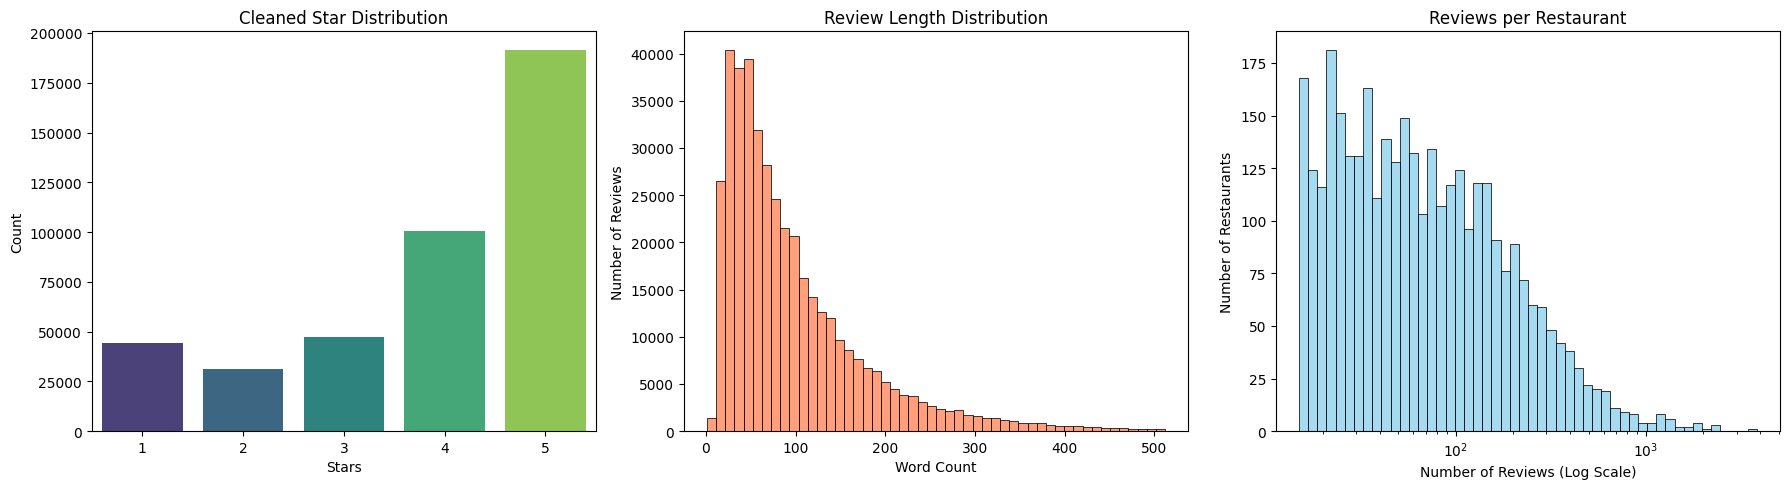

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=clean_review, x='stars', ax=axes[0], palette='viridis')
axes[0].set_title('Cleaned Star Distribution')
axes[0].set_xlabel('Stars')
axes[0].set_ylabel('Count')


word_counts = clean_review['text'].str.split().str.len()
sns.histplot(word_counts[word_counts <= 512], bins=50, ax=axes[1], color='coral')
axes[1].set_title('Review Length Distribution')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Number of Reviews')

reviews_per_restaurant = clean_review.groupby('business_id').size()
sns.histplot(reviews_per_restaurant, bins=50, log_scale=(True, False), ax=axes[2], color='skyblue')
axes[2].set_title('Reviews per Restaurant')
axes[2].set_xlabel('Number of Reviews (Log Scale)')
axes[2].set_ylabel('Number of Restaurants')

plt.tight_layout()
plt.show()

- The dataset is overwhelmingly positive (Chart 1 - left-skewed). Five-star reviews are the dominant class by a wide margin (approaching 200,000 reviews), with 4-star reviews coming in second at around 100,000. May need to use class weighting or under-sampling to ensure the model learns negative themes effectively.
- The word count distribution is heavily right-skewed, with the vast majority of reviews clustering tightly between 20 and 150 words
- After filtering for more than 15 reviews, the distribution (on logarithmic scale) shows that most restaurants still sit on between 15 and 100 reviews. But there is still a small handful of highly popular "superstar" restaurants with over 1,000 reviews